# COVID-19 and Lung Disease Detection from Chest X-rays
In this notebook, we will train a CNN classifier to categorize chest X-ray images into four classes: **COVID-19**, **Lung opacity**, **Viral pneumonia**, and **Normal**.

We will cover:
1. **Data Download & Loading**
2. **Exploratory Data Analysis (EDA)**
3. **Data Splitting**
4. **Preprocessing & Augmentation**
5. **Model Building & Transfer Learning**
6. **Model Training & Validation**
7. **Model Evaluation & Metrics**
8. **Grad-CAM Visualization for Interpretability**

In [2]:
# Kaggle API credentials: upload your own kaggle.json to Colab (never paste the key into a notebook)
import os
os.makedirs('/root/.kaggle/', exist_ok=True)
# !cp kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json
print("Kaggle API successfully configured.")


Kaggle API successfully configured.


In [3]:
# Download and unzip the dataset
!kaggle datasets download -d tawsifurrahman/covid19-radiography-database
!unzip -q covid19-radiography-database.zip -d covid19_data
print("Dataset downloaded and unzipped successfully.")

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database
License(s): copyright-authors
100% 778M/778M [00:06<00:00, 122MB/s]

Dataset downloaded and unzipped successfully.


In [4]:
# Load and explore dataset structure
import glob

base_dir = 'covid19_data/COVID-19_Radiography_Dataset'
categories = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

for cat in categories:
    path = os.path.join(base_dir, cat, 'images/*')
    images = glob.glob(path)
    print(f"{cat}: {len(images)} images")

COVID: 3616 images
Lung_Opacity: 6012 images
Normal: 10192 images
Viral Pneumonia: 1345 images


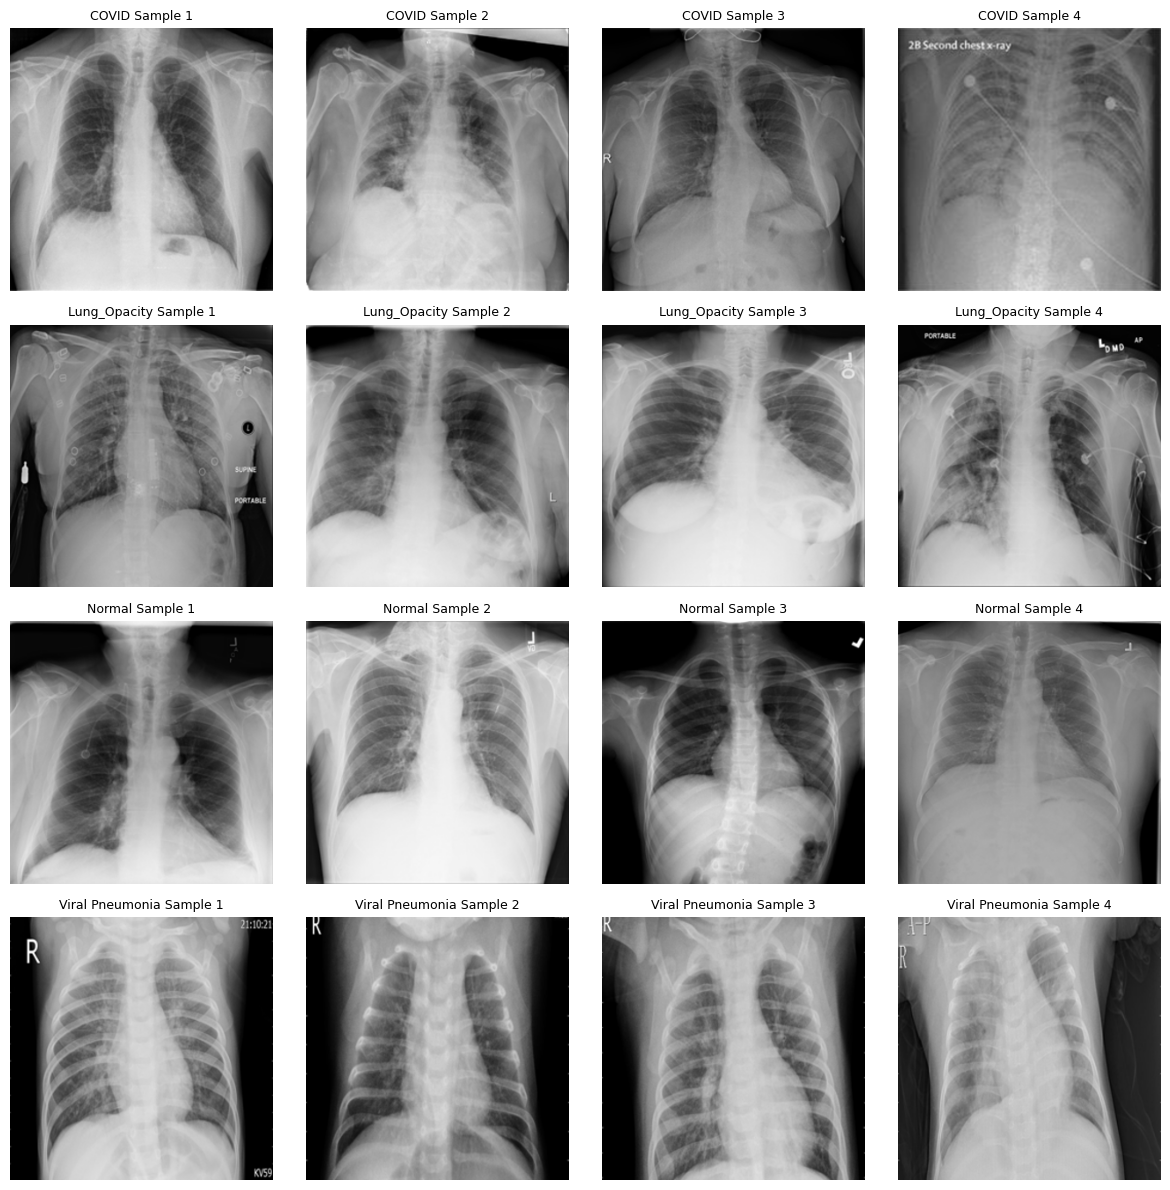

In [5]:
import os
import glob
import random
import matplotlib.pyplot as plt
import cv2

base_dir = 'covid19_data/COVID-19_Radiography_Dataset'
categories = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

# Visualize samples
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for i, cat in enumerate(categories):
    path = os.path.join(base_dir, cat, 'images/*')
    images = glob.glob(path)
    selected_images = random.sample(images, 4)
    for j, img_path in enumerate(selected_images):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{cat} Sample {j+1}", fontsize=9)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split

# Create a structured list of image paths and corresponding labels
all_paths = []
all_labels = []

for label_idx, cat in enumerate(categories):
    path = os.path.join(base_dir, cat, 'images/*')
    images = sorted(glob.glob(path))
    all_paths.extend(images)
    all_labels.extend([label_idx] * len(images))

# Split data using Stratified Split with fixed seed (random_state=42) to preserve balance
train_paths, test_paths, train_labels, test_labels = train_test_split(
    all_paths, all_labels, test_size=0.15, random_state=42, stratify=all_labels
)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels, test_size=0.15, random_state=42, stratify=train_labels
)

print(f"Train size: {len(train_paths)}")
print(f"Val size: {len(val_paths)}")
print(f"Test size: {len(test_paths)}")

Train size: 15291
Val size: 2699
Test size: 3175


In [7]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import pandas as pd

# Convert to DataFrames for ImageDataGenerator flow_from_dataframe
train_df = pd.DataFrame({'filename': train_paths, 'class': [categories[l] for l in train_labels]})
val_df = pd.DataFrame({'filename': val_paths, 'class': [categories[l] for l in val_labels]})
test_df = pd.DataFrame({'filename': test_paths, 'class': [categories[l] for l in test_labels]})

# Setup augmentations and dataloaders
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_generator = train_datagen.flow_from_dataframe(
    train_df, x_col='filename', y_col='class',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', seed=42
)

val_generator = val_test_datagen.flow_from_dataframe(
    val_df, x_col='filename', y_col='class',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    test_df, x_col='filename', y_col='class',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

Found 15291 validated image filenames belonging to 4 classes.
Found 2699 validated image filenames belonging to 4 classes.
Found 3175 validated image filenames belonging to 4 classes.


In [8]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Transfer learning using MobileNetV2 for medical classification efficiency
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze layers first

x = layers.GlobalAveragePooling2D()(base_model.output)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation='softmax')(x)

model = models.Model(inputs=base_model.input, outputs=outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
# Train the model
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator,
    verbose=1
)

Epoch 1/10
478/478 ━━━━━━━━━━━━━━━━━━━━ 262s 522ms/step - accuracy: 0.7820 - loss: 0.5768 - val_accuracy: 0.8107 - val_loss: 0.4885
Epoch 2/10
478/478 ━━━━━━━━━━━━━━━━━━━━ 219s 458ms/step - accuracy: 0.8287 - loss: 0.4562 - val_accuracy: 0.8381 - val_loss: 0.4088
Epoch 3/10
478/478 ━━━━━━━━━━━━━━━━━━━━ 220s 460ms/step - accuracy: 0.8360 - loss: 0.4275 - val_accuracy: 0.8511 - val_loss: 0.3936
Epoch 4/10
478/478 ━━━━━━━━━━━━━━━━━━━━ 210s 440ms/step - accuracy: 0.8434 - loss: 0.4064 - val_accuracy: 0.8522 - val_loss: 0.3783
Epoch 5/10
478/478 ━━━━━━━━━━━━━━━━━━━━ 220s 461ms/step - accuracy: 0.8493 - loss: 0.3950 - val_accuracy: 0.8640 - val_loss: 0.3502
Epoch 6/10
478/478 ━━━━━━━━━━━━━━━━━━━━ 212s 443ms/step - accuracy: 0.8578 - loss: 0.3776 - val_accuracy: 0.8629 - val_loss: 0.3517
Epoch 7/10
478/478 ━━━━━━━━━━━━━━━━━━━━ 218s 457ms/step - accuracy: 0.8605 - loss: 0.3761 - val_accuracy: 0.8685 - val_loss: 0.3395
Epoch 8/10
478/478 ━━━━━━━━━━━━━━━━━━━━ 205s 430ms/step - accuracy: 0.8651 -

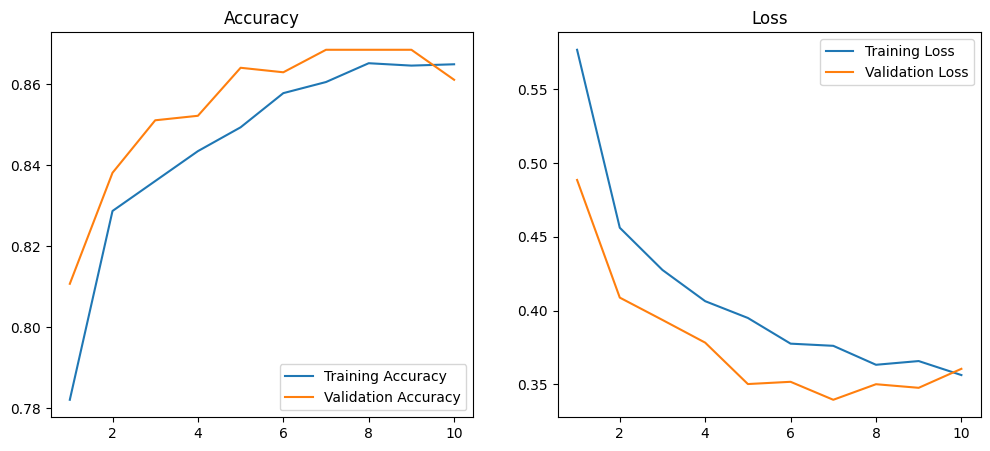

In [10]:
# Plot Training & Validation Metrics
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Loss')
plt.legend()
plt.show()

100/100 ━━━━━━━━━━━━━━━━━━━━ 29s 222ms/step
                 precision    recall  f1-score   support

          COVID       0.81      0.90      0.85       542
   Lung_Opacity       0.93      0.71      0.81       902
         Normal       0.85      0.95      0.90      1529
Viral Pneumonia       0.96      0.88      0.92       202

       accuracy                           0.87      3175
      macro avg       0.89      0.86      0.87      3175
   weighted avg       0.88      0.87      0.87      3175



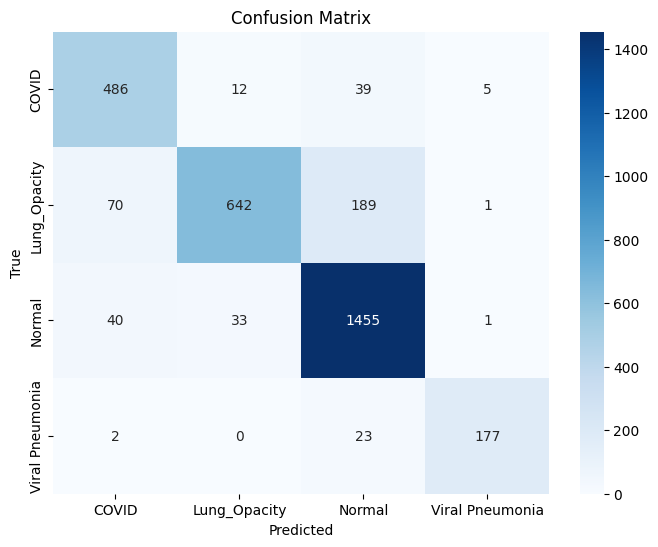

In [11]:
# Evaluate model on Test dataset
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

test_generator.reset()
predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

# Metrics Report
print(classification_report(y_true, y_pred, target_names=categories))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=categories, yticklabels=categories, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

Total misclassified images: 415


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


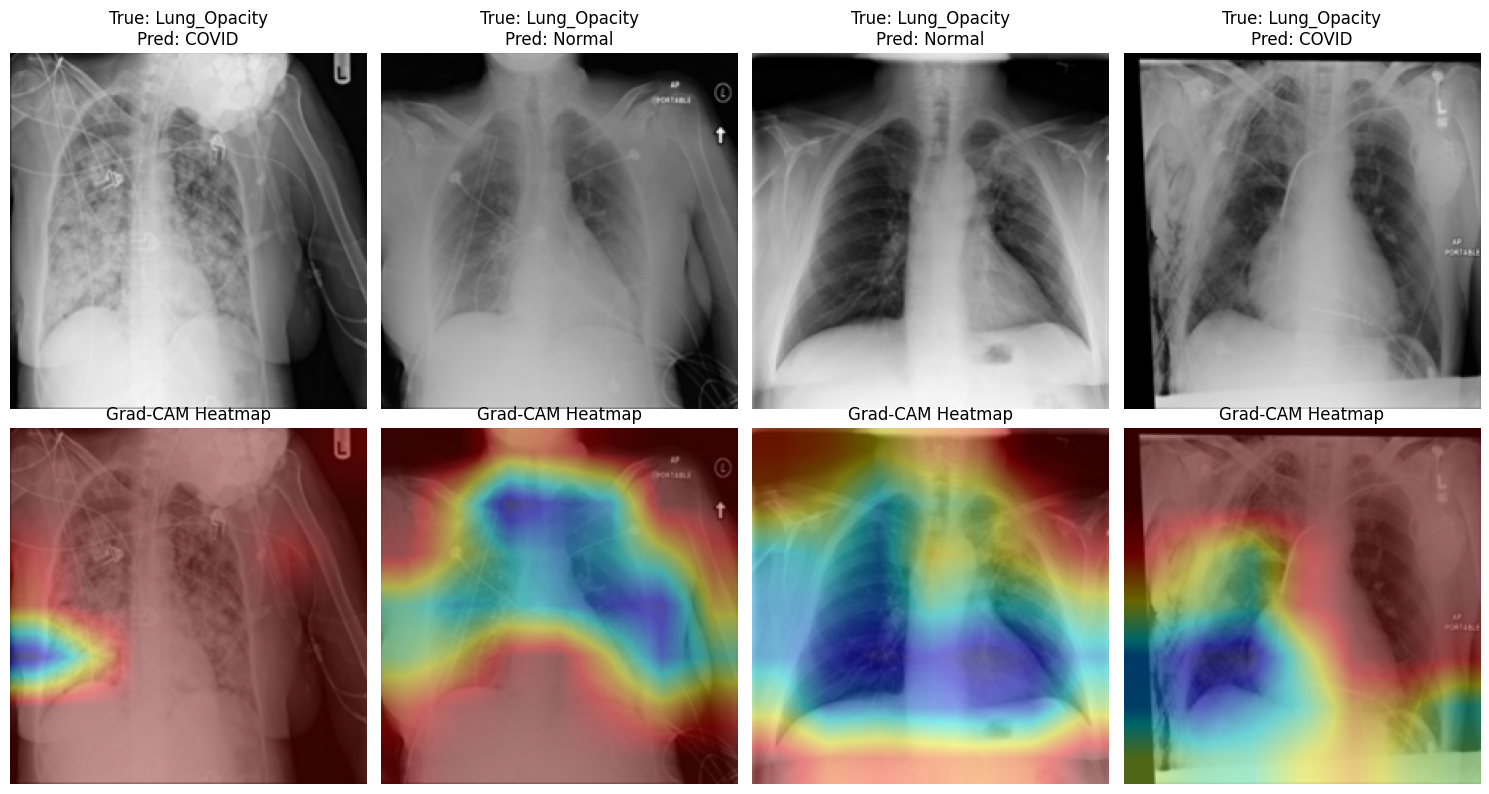

In [12]:
# Identify Misclassified Test Images & Saliency / Grad-CAM implementation
import cv2

misclassified_indices = np.where(y_pred != y_true)[0]
print(f"Total misclassified images: {len(misclassified_indices)}")

def get_gradcam(model, img_array, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

# Plot misclassified samples with their actual/predicted labels and Grad-CAM overlays
plt.figure(figsize=(15, 8))
for idx, m_idx in enumerate(misclassified_indices[:4]):
    img_path = test_df.iloc[m_idx]['filename']
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (224, 224)) / 255.0
    img_input = np.expand_dims(img_resized, axis=0)

    # Generate heatmap using last block of MobileNetV2
    heatmap = get_gradcam(model, img_input, 'Conv_1')
    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(np.uint8(255 * img_resized), 0.6, heatmap, 0.4, 0)

    plt.subplot(2, 4, idx + 1)
    plt.imshow(img_resized)
    plt.title(f"True: {categories[y_true[m_idx]]}\nPred: {categories[y_pred[m_idx]]}")
    plt.axis('off')

    plt.subplot(2, 4, idx + 5)
    plt.imshow(superimposed_img)
    plt.title("Grad-CAM Heatmap")
    plt.axis('off')
plt.tight_layout()
plt.show()